In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import time
from numpy.random import default_rng

matplotlib.rcParams['figure.dpi'] = 120


In [2]:
bank = pd.read_csv('bank.csv', sep=';')
print(f'Shape: {bank.shape}')
print(f'\nColumn dtypes:')
print(bank.dtypes)
print(f'\nActual NaN count: {bank.isna().sum().sum()}')
print(f"Rows containing 'unknown': {(bank == 'unknown').any(axis=1).sum()}")
bank.head()


Shape: (4521, 17)

Column dtypes:
age           int64
job          object
marital      object
education    object
default      object
balance       int64
housing      object
loan         object
contact      object
day           int64
month        object
duration      int64
campaign      int64
pdays         int64
previous      int64
poutcome     object
y            object
dtype: object

Actual NaN count: 0
Rows containing 'unknown': 3757


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


In [3]:
# Check if binary columns have 'unknown'
binary_cols = ['default', 'housing', 'loan']
for col in binary_cols:
    n_unknown = (bank[col] == 'unknown').sum()
    print(f"  '{col}' has {n_unknown} unknown rows")

# Map binary yes/no → 1/0
for col in binary_cols:
    bank[col] = bank[col].map({'yes': 1, 'no': 0})

# Target
bank['y'] = bank['y'].map({'yes': 1, 'no': 0})

# One-hot encode the 6 multi-class text columns
cat_cols = ['job', 'marital', 'education', 'contact', 'month', 'poutcome']
bank = pd.get_dummies(bank, columns=cat_cols, drop_first=False)

print(f'\nShape after encoding: {bank.shape}')
print(f'NaN remaining: {bank.isna().sum().sum()}')
print(f'\nTarget distribution:')
print(bank['y'].value_counts())
print(f'  → Class imbalance: {bank["y"].mean()*100:.1f}% positives')


  'default' has 0 unknown rows
  'housing' has 0 unknown rows
  'loan' has 0 unknown rows

Shape after encoding: (4521, 49)
NaN remaining: 0

Target distribution:
0    4000
1     521
Name: y, dtype: int64
  → Class imbalance: 11.5% positives


In [4]:
rng = default_rng(42)

bank_arr = bank.to_numpy().astype(float)
rng.shuffle(bank_arr)

n_bank   = bank_arr.shape[0]
split    = int(0.8 * n_bank)

y_col_idx    = bank.columns.get_loc('y')
feature_cols = [i for i in range(bank_arr.shape[1]) if i != y_col_idx]

X_bank_train = bank_arr[:split,  feature_cols]
X_bank_test  = bank_arr[split:,  feature_cols]
y_bank_train = bank_arr[:split,  y_col_idx]
y_bank_test  = bank_arr[split:,  y_col_idx]

# Normalize using training statistics only
mean_bank             = X_bank_train.mean(axis=0)
std_bank              = X_bank_train.std(axis=0)
std_bank[std_bank==0] = 1

X_bank_train = (X_bank_train - mean_bank) / std_bank
X_bank_test  = (X_bank_test  - mean_bank) / std_bank

# Add bias column
X_bank_train = np.hstack([np.ones((X_bank_train.shape[0], 1)), X_bank_train])
X_bank_test  = np.hstack([np.ones((X_bank_test.shape[0],  1)), X_bank_test])

print(f'Train: {X_bank_train.shape}')
print(f'Test:  {X_bank_test.shape}')
print(f'Train class balance: {y_bank_train.mean()*100:.1f}% positives')
print(f'Test  class balance: {y_bank_test.mean()*100:.1f}% positives')


Train: (3616, 49)
Test:  (905, 49)
Train class balance: 11.6% positives
Test  class balance: 11.2% positives


In [5]:
wine_red   = pd.read_csv('../Exercise 3/winequality-red.csv',   sep=';')
wine_white = pd.read_csv('../Exercise 3/winequality-white.csv', sep=';')

wine_red['color']   = 0   # red   → 0
wine_white['color'] = 1   # white → 1

wine = pd.concat([wine_red, wine_white], ignore_index=True)

print(f'Red:      {wine_red.shape}')
print(f'White:    {wine_white.shape}')
print(f'Combined: {wine.shape}')
print(f'\nNaN count: {wine.isna().sum().sum()}')
print(f'\nTarget (quality) distribution:')
print(wine['quality'].value_counts().sort_index())
print(f'\nQuality range: {wine["quality"].min()} – {wine["quality"].max()}')
wine.head(3)



Red:      (1599, 13)
White:    (4898, 13)
Combined: (6497, 13)

NaN count: 0

Target (quality) distribution:
3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
Name: quality, dtype: int64

Quality range: 3 – 9


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0


In [6]:
rng2 = default_rng(42)

wine_arr = wine.to_numpy().astype(float)
rng2.shuffle(wine_arr)

n_wine    = wine_arr.shape[0]
split_w   = int(0.8 * n_wine)

y_wine_idx  = wine.columns.get_loc('quality')
feat_wine   = [i for i in range(wine_arr.shape[1]) if i != y_wine_idx]

X_wine_train = wine_arr[:split_w, feat_wine]
X_wine_test  = wine_arr[split_w:, feat_wine]
y_wine_train = wine_arr[:split_w, y_wine_idx]
y_wine_test  = wine_arr[split_w:, y_wine_idx]

# Normalize with training stats only
mean_wine             = X_wine_train.mean(axis=0)
std_wine              = X_wine_train.std(axis=0)
std_wine[std_wine==0] = 1

X_wine_train = (X_wine_train - mean_wine) / std_wine
X_wine_test  = (X_wine_test  - mean_wine) / std_wine

# Add bias column
X_wine_train = np.hstack([np.ones((X_wine_train.shape[0], 1)), X_wine_train])
X_wine_test  = np.hstack([np.ones((X_wine_test.shape[0],  1)), X_wine_test])

print(f'Train: {X_wine_train.shape}')
print(f'Test:  {X_wine_test.shape}')
print(f'Train quality mean: {y_wine_train.mean():.3f}')
print(f'Test  quality mean: {y_wine_test.mean():.3f}')


Train: (5197, 13)
Test:  (1300, 13)
Train quality mean: 5.814
Test  quality mean: 5.837


In [7]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1.0 / (1.0 + np.exp(-z))

def rmse(beta, X, y):
    residuals = X @ beta - y
    return np.sqrt(np.mean(residuals ** 2))

def log_loss(beta, X, y):
    y_hat = np.clip(sigmoid(X @ beta), 1e-12, 1 - 1e-12)
    return -np.mean(y * np.log(y_hat) + (1 - y) * np.log(1 - y_hat))

def grad_batch_regression(beta, X_b, y_b, lam):
    B          = X_b.shape[0]
    residuals  = X_b @ beta - y_b
    grad_data  = (1/B) * X_b.T @ residuals
    grad_reg   = lam * beta
    return grad_data + grad_reg

def grad_batch_logreg(beta, X_b, y_b, lam):
    B          = X_b.shape[0]
    y_hat      = sigmoid(X_b @ beta)
    grad_data  = (1/B) * X_b.T @ (y_hat - y_b)
    grad_reg   = lam * beta
    return grad_data + grad_reg

print('Core functions ready.')


Core functions ready.


In [8]:
def mini_bgd(X_train, y_train, X_test, y_test,
             grad_fn, loss_fn,
             alpha=0.01, lam=0.01, batch_size=50,
             imax=200, epsilon=1e-6, seed=42):

    rng_l = default_rng(seed)
    N, M  = X_train.shape
    beta  = np.zeros(M)

    train_losses = []
    test_losses  = []

    for epoch in range(imax):
        # Step 1: shuffle the training data
        idx    = rng_l.permutation(N)
        X_shuf = X_train[idx]
        y_shuf = y_train[idx]

        # Step 2: process each mini-batch
        for b_start in range(0, N, batch_size):
            X_b = X_shuf[b_start : b_start + batch_size]
            y_b = y_shuf[b_start : b_start + batch_size]
            g   = grad_fn(beta, X_b, y_b, lam)
            beta = beta - alpha * g

        # Step 3: record losses on full dataset after the epoch
        train_losses.append(loss_fn(beta, X_train, y_train))
        test_losses.append(loss_fn(beta, X_test,  y_test))

        # Step 4: convergence check
        if epoch > 0 and abs(train_losses[-1] - train_losses[-2]) < epsilon:
            print(f'  Converged at epoch {epoch + 1}')
            break

    return beta, train_losses, test_losses

print('mini_bgd ready.')


mini_bgd ready.


In [9]:
alphas  = [0.001, 0.01, 0.1]
lambdas = [0.0001, 0.01, 1.0]

# Store results: results_wine[alpha][lambda] = (beta, train_losses, test_losses)
results_wine = {}

print('=== Wine Quality — Ridge Regression (Mini-BGD) ===\n')
for alpha in alphas:
    results_wine[alpha] = {}
    for lam in lambdas:
        t0 = time.time()
        beta, train_l, test_l = mini_bgd(
            X_wine_train, y_wine_train, X_wine_test, y_wine_test,
            grad_fn    = grad_batch_regression,
            loss_fn    = rmse,
            alpha      = alpha,
            lam        = lam,
            batch_size = 50,
            imax       = 200,
            epsilon    = 1e-6
        )
        elapsed = time.time() - t0
        results_wine[alpha][lam] = (beta, train_l, test_l)
        print(f'  α={alpha:.3f}  λ={lam:.4f}  →  '
              f'Train RMSE: {train_l[-1]:.4f}  '
              f'Test RMSE: {test_l[-1]:.4f}  '
              f'Epochs: {len(train_l)}  ({elapsed:.1f}s)')
    print()


=== Wine Quality — Ridge Regression (Mini-BGD) ===

  α=0.001  λ=0.0001  →  Train RMSE: 0.7378  Test RMSE: 0.7153  Epochs: 200  (0.5s)
  Converged at epoch 132
  α=0.001  λ=0.0100  →  Train RMSE: 0.7405  Test RMSE: 0.7190  Epochs: 132  (0.4s)
  α=0.001  λ=1.0000  →  Train RMSE: 3.0090  Test RMSE: 3.0205  Epochs: 200  (0.5s)

  α=0.010  λ=0.0001  →  Train RMSE: 0.7372  Test RMSE: 0.7139  Epochs: 200  (0.4s)
  α=0.010  λ=0.0100  →  Train RMSE: 0.7397  Test RMSE: 0.7177  Epochs: 200  (0.4s)
  α=0.010  λ=1.0000  →  Train RMSE: 3.0108  Test RMSE: 3.0228  Epochs: 200  (0.4s)

  α=0.100  λ=0.0001  →  Train RMSE: 0.7403  Test RMSE: 0.7123  Epochs: 200  (0.4s)
  α=0.100  λ=0.0100  →  Train RMSE: 0.7443  Test RMSE: 0.7184  Epochs: 200  (0.4s)
  α=0.100  λ=1.0000  →  Train RMSE: 3.0473  Test RMSE: 3.0606  Epochs: 200  (0.4s)



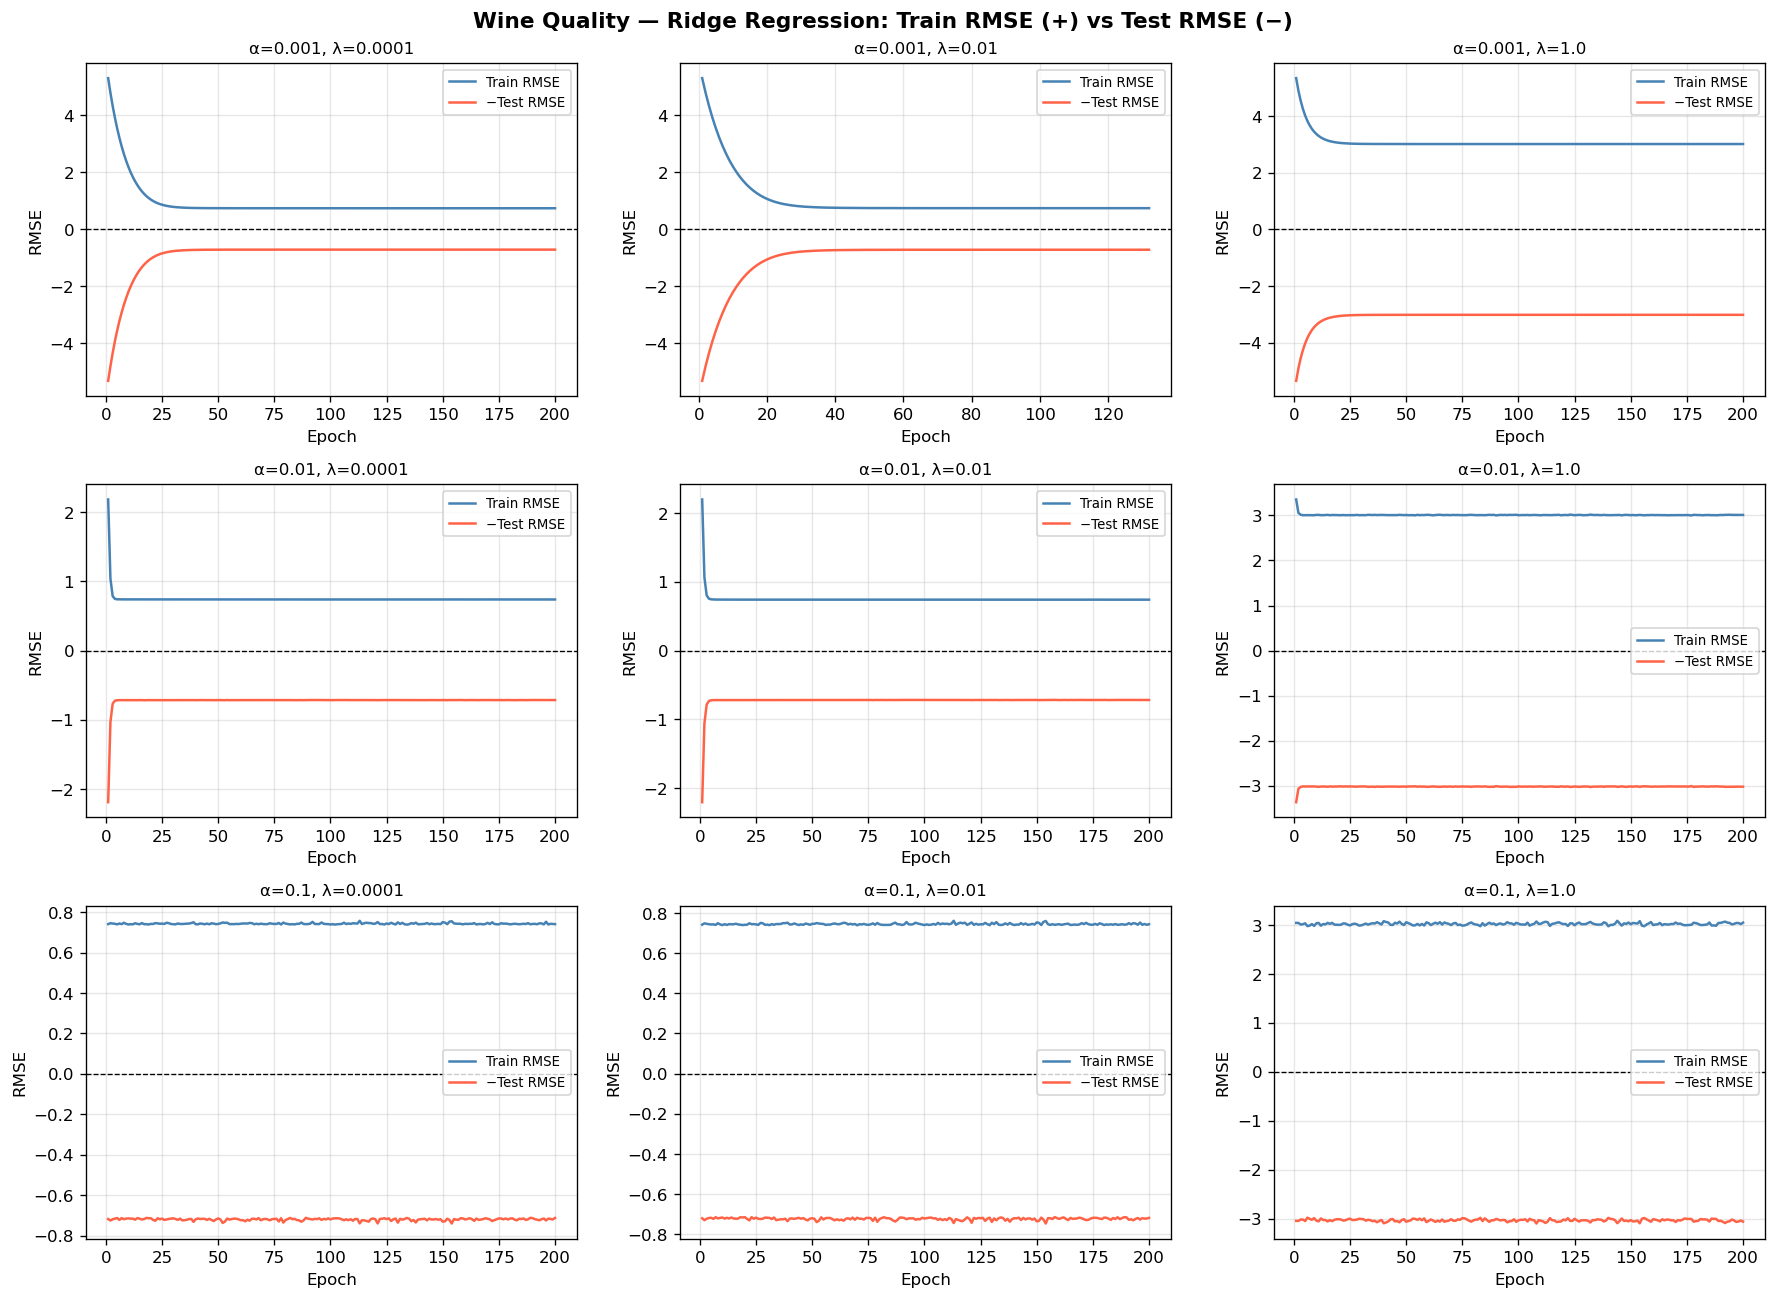

Saved: fig_wine_ex1.png


In [10]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
fig.suptitle('Wine Quality — Ridge Regression: Train RMSE (+) vs Test RMSE (−)',
             fontsize=13, fontweight='bold')

for row, alpha in enumerate(alphas):
    for col, lam in enumerate(lambdas):
        beta, train_l, test_l = results_wine[alpha][lam]
        ax = axes[row, col]
        epochs = range(1, len(train_l) + 1)

        ax.plot(epochs,  train_l, color='steelblue', linewidth=1.5, label='Train RMSE')
        ax.plot(epochs, [-v for v in test_l], color='tomato', linewidth=1.5, label='−Test RMSE')
        ax.axhline(0, color='black', linewidth=0.8, linestyle='--')

        ax.set_title(f'α={alpha}, λ={lam}', fontsize=10)
        ax.set_xlabel('Epoch')
        ax.set_ylabel('RMSE')
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('fig_wine_ex1.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: fig_wine_ex1.png')


In [11]:
results_bank = {}

print('=== Bank Marketing — Regularized Logistic Regression (Mini-BGD) ===\n')
for alpha in alphas:
    results_bank[alpha] = {}
    for lam in lambdas:
        t0 = time.time()
        beta, train_l, test_l = mini_bgd(
            X_bank_train, y_bank_train, X_bank_test, y_bank_test,
            grad_fn    = grad_batch_logreg,
            loss_fn    = log_loss,
            alpha      = alpha,
            lam        = lam,
            batch_size = 50,
            imax       = 200,
            epsilon    = 1e-6
        )
        elapsed = time.time() - t0
        results_bank[alpha][lam] = (beta, train_l, test_l)
        print(f'  α={alpha:.3f}  λ={lam:.4f}  →  '
              f'Train Loss: {train_l[-1]:.4f}  '
              f'Test Loss: {test_l[-1]:.4f}  '
              f'Epochs: {len(train_l)}  ({elapsed:.1f}s)')
    print()


=== Bank Marketing — Regularized Logistic Regression (Mini-BGD) ===

  α=0.001  λ=0.0001  →  Train Loss: 0.2682  Test Loss: 0.2540  Epochs: 200  (1.2s)
  α=0.001  λ=0.0100  →  Train Loss: 0.2746  Test Loss: 0.2611  Epochs: 200  (1.0s)
  Converged at epoch 94
  α=0.001  λ=1.0000  →  Train Loss: 0.5609  Test Loss: 0.5607  Epochs: 94  (0.5s)

  Converged at epoch 148
  α=0.010  λ=0.0001  →  Train Loss: 0.2447  Test Loss: 0.2297  Epochs: 148  (0.8s)
  Converged at epoch 125
  α=0.010  λ=0.0100  →  Train Loss: 0.2522  Test Loss: 0.2374  Epochs: 125  (0.7s)
  α=0.010  λ=1.0000  →  Train Loss: 0.5613  Test Loss: 0.5608  Epochs: 200  (1.1s)

  Converged at epoch 38
  α=0.100  λ=0.0001  →  Train Loss: 0.2448  Test Loss: 0.2299  Epochs: 38  (0.2s)
  α=0.100  λ=0.0100  →  Train Loss: 0.2525  Test Loss: 0.2369  Epochs: 200  (1.0s)
  α=0.100  λ=1.0000  →  Train Loss: 0.5649  Test Loss: 0.5635  Epochs: 200  (1.1s)



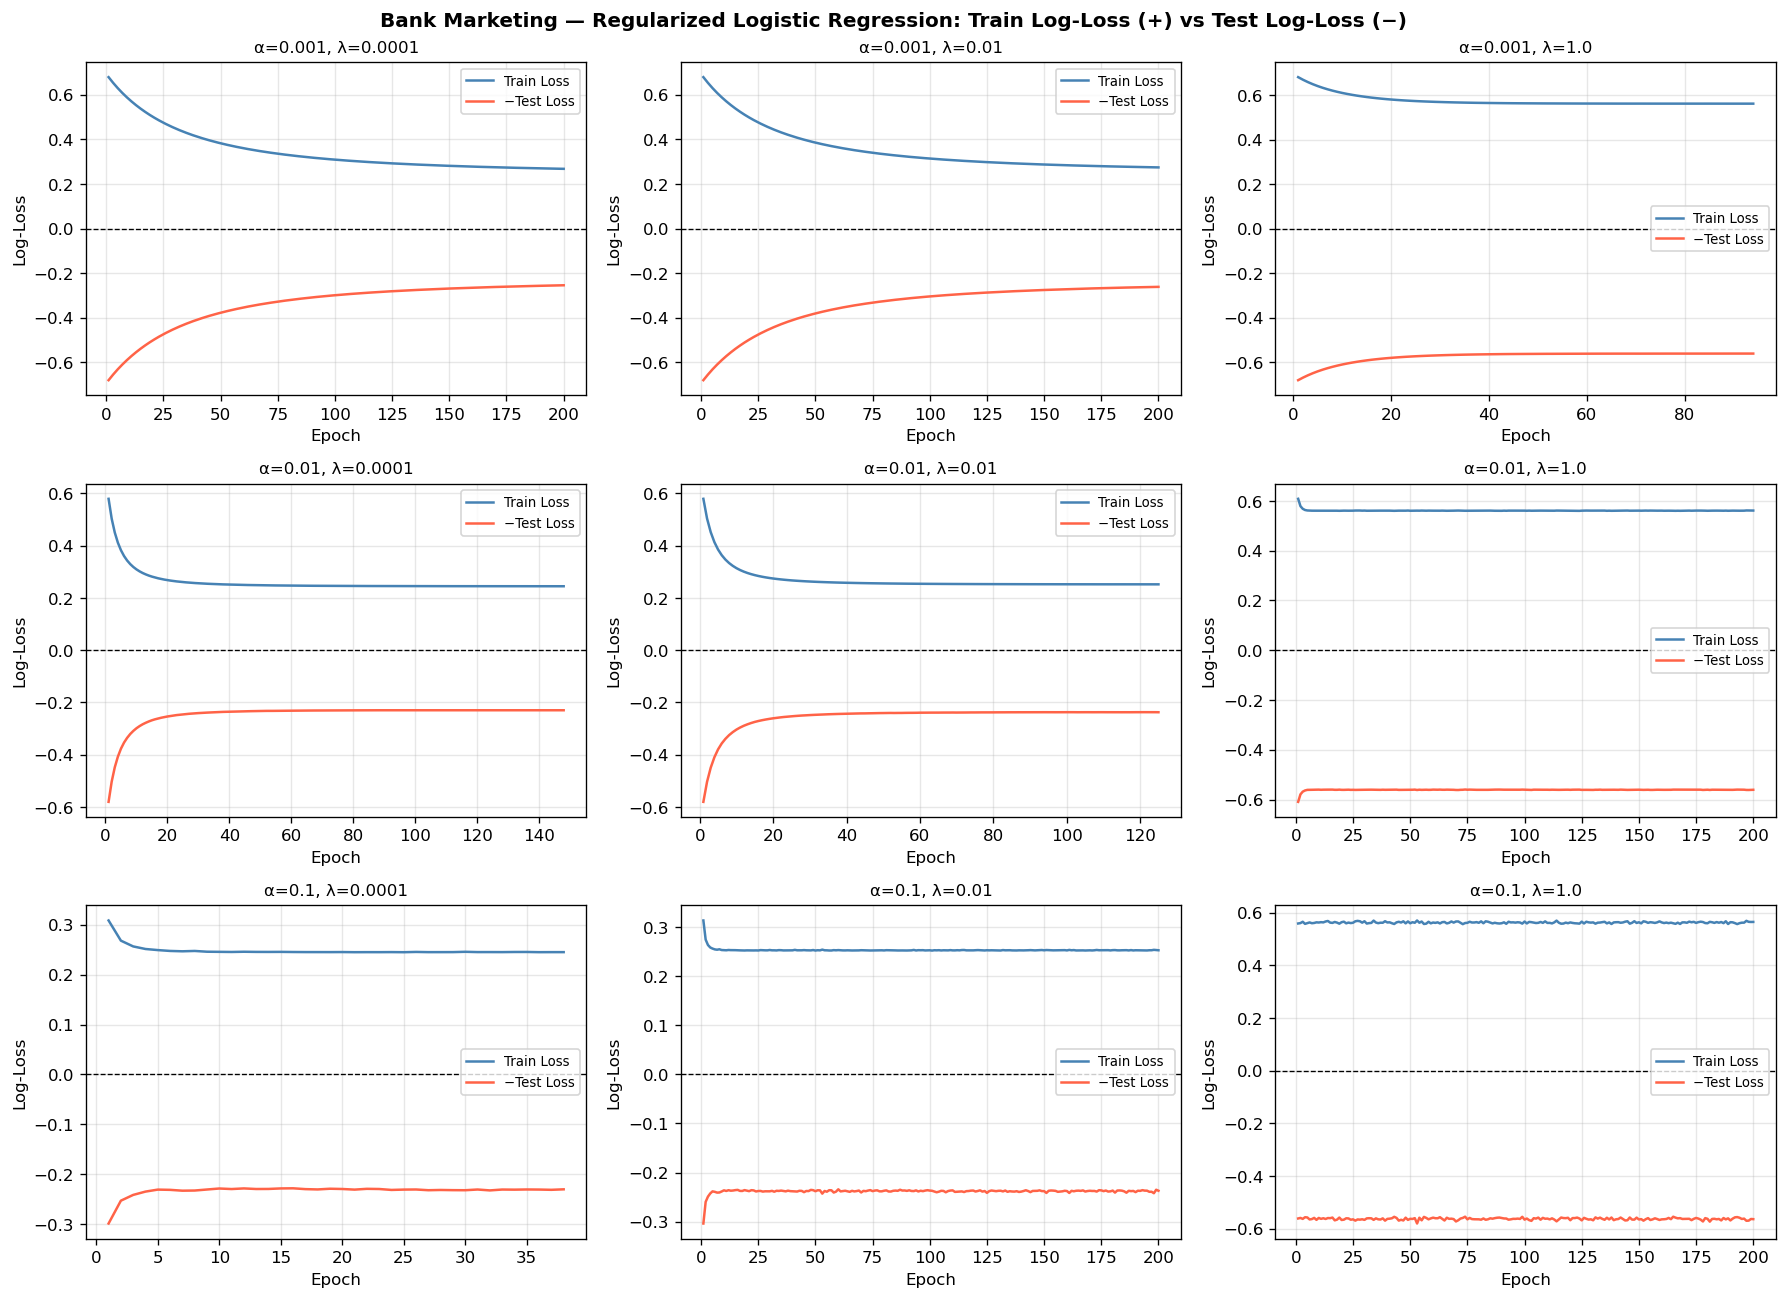

Saved: fig_bank_ex1.png


In [12]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
fig.suptitle('Bank Marketing — Regularized Logistic Regression: Train Log-Loss (+) vs Test Log-Loss (−)',
             fontsize=12, fontweight='bold')

for row, alpha in enumerate(alphas):
    for col, lam in enumerate(lambdas):
        beta, train_l, test_l = results_bank[alpha][lam]
        ax = axes[row, col]
        epochs = range(1, len(train_l) + 1)

        ax.plot(epochs,  train_l,            color='steelblue', linewidth=1.5, label='Train Loss')
        ax.plot(epochs, [-v for v in test_l], color='tomato',    linewidth=1.5, label='−Test Loss')
        ax.axhline(0, color='black', linewidth=0.8, linestyle='--')

        ax.set_title(f'α={alpha}, λ={lam}', fontsize=10)
        ax.set_xlabel('Epoch')
        ax.set_ylabel('Log-Loss')
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('fig_bank_ex1.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: fig_bank_ex1.png')


In [13]:
def kfold_cv(X_train, y_train, grad_fn, loss_fn,
             alpha, lam, batch_size=50, imax=200, epsilon=1e-6, k=5, seed=42):

    N       = X_train.shape[0]
    rng_cv  = default_rng(seed)
    indices = rng_cv.permutation(N)        # random ordering of all row indices
    fold_size = N // k                     # how many rows per fold

    val_losses = []

    for fold in range(k):
        val_start = fold * fold_size
        val_end   = val_start + fold_size if fold < k - 1 else N

        val_idx   = indices[val_start : val_end]
        train_idx = np.concatenate([indices[:val_start], indices[val_end:]])

        X_tr  = X_train[train_idx];  y_tr  = y_train[train_idx]
        X_val = X_train[val_idx];    y_val = y_train[val_idx]

        beta, _, _ = mini_bgd(X_tr, y_tr, X_val, y_val,
                              grad_fn=grad_fn, loss_fn=loss_fn,
                              alpha=alpha, lam=lam,
                              batch_size=batch_size, imax=imax,
                              epsilon=epsilon, seed=seed)

        val_losses.append(loss_fn(beta, X_val, y_val))

    return np.mean(val_losses)

print('kfold_cv ready.')


kfold_cv ready.


In [14]:
alphas_grid  = [0.001, 0.01, 0.05, 0.1]
lambdas_grid = [0.0001, 0.001, 0.01, 0.1]

print('=== Grid Search: Wine Quality (k=5 CV) ===\n')
cv_scores_wine = np.zeros((len(alphas_grid), len(lambdas_grid)))

for i, alpha in enumerate(alphas_grid):
    for j, lam in enumerate(lambdas_grid):
        score = kfold_cv(
            X_wine_train, y_wine_train,
            grad_fn=grad_batch_regression, loss_fn=rmse,
            alpha=alpha, lam=lam, batch_size=50, imax=200, epsilon=1e-6
        )
        cv_scores_wine[i, j] = score
        print(f'  α={alpha:.3f}  λ={lam:.4f}  →  Mean CV RMSE: {score:.4f}')
    print()

best_i, best_j = np.unravel_index(np.argmin(cv_scores_wine), cv_scores_wine.shape)
best_alpha_wine = alphas_grid[best_i]
best_lam_wine   = lambdas_grid[best_j]
print(f'Best: α={best_alpha_wine}, λ={best_lam_wine}  →  CV RMSE={cv_scores_wine[best_i, best_j]:.4f}')


=== Grid Search: Wine Quality (k=5 CV) ===

  Converged at epoch 161
  Converged at epoch 132
  Converged at epoch 132
  Converged at epoch 132
  Converged at epoch 142
  α=0.001  λ=0.0001  →  Mean CV RMSE: 0.7398
  Converged at epoch 161
  Converged at epoch 147
  Converged at epoch 149
  Converged at epoch 127
  Converged at epoch 142
  α=0.001  λ=0.0010  →  Mean CV RMSE: 0.7398
  Converged at epoch 126
  Converged at epoch 112
  Converged at epoch 153
  Converged at epoch 158
  Converged at epoch 145
  α=0.001  λ=0.0100  →  Mean CV RMSE: 0.7421
  Converged at epoch 180
  Converged at epoch 178
  α=0.001  λ=0.1000  →  Mean CV RMSE: 0.9112

  Converged at epoch 140
  Converged at epoch 118
  Converged at epoch 166
  Converged at epoch 13
  α=0.010  λ=0.0001  →  Mean CV RMSE: 0.7400
  Converged at epoch 51
  Converged at epoch 193
  Converged at epoch 86
  α=0.010  λ=0.0010  →  Mean CV RMSE: 0.7388
  Converged at epoch 87
  Converged at epoch 89
  Converged at epoch 199
  α=0.010  λ=0.

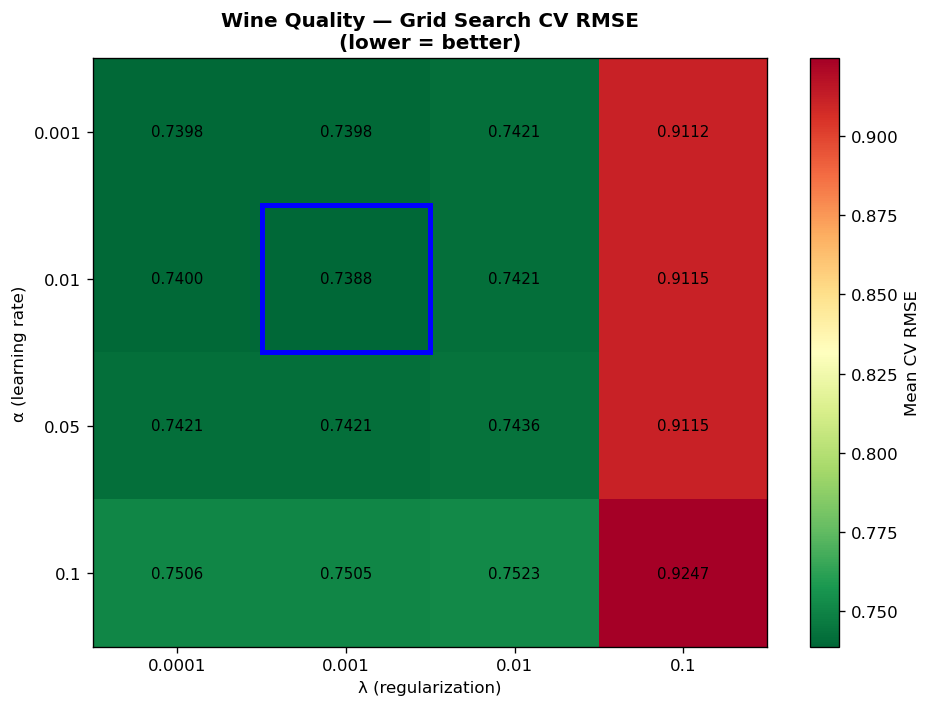

Saved: fig_wine_gridsearch.png
Best: α=0.01, λ=0.001


In [15]:
fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(cv_scores_wine, cmap='RdYlGn_r', aspect='auto')
plt.colorbar(im, ax=ax, label='Mean CV RMSE')

ax.set_xticks(range(len(lambdas_grid)))
ax.set_yticks(range(len(alphas_grid)))
ax.set_xticklabels([str(l) for l in lambdas_grid])
ax.set_yticklabels([str(a) for a in alphas_grid])
ax.set_xlabel('λ (regularization)')
ax.set_ylabel('α (learning rate)')
ax.set_title('Wine Quality — Grid Search CV RMSE\n(lower = better)', fontweight='bold')

for i in range(len(alphas_grid)):
    for j in range(len(lambdas_grid)):
        ax.text(j, i, f'{cv_scores_wine[i,j]:.4f}',
                ha='center', va='center', fontsize=9,
                color='black')

ax.add_patch(plt.Rectangle((best_j-0.5, best_i-0.5), 1, 1,
                             fill=False, edgecolor='blue', linewidth=3))

plt.tight_layout()
plt.savefig('fig_wine_gridsearch.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: fig_wine_gridsearch.png')
print(f'Best: α={best_alpha_wine}, λ={best_lam_wine}')


In [16]:
print('=== Grid Search: Bank Marketing (k=5 CV) ===\n')
cv_scores_bank = np.zeros((len(alphas_grid), len(lambdas_grid)))

for i, alpha in enumerate(alphas_grid):
    for j, lam in enumerate(lambdas_grid):
        score = kfold_cv(
            X_bank_train, y_bank_train,
            grad_fn=grad_batch_logreg, loss_fn=log_loss,
            alpha=alpha, lam=lam, batch_size=50, imax=200, epsilon=1e-6
        )
        cv_scores_bank[i, j] = score
        print(f'  α={alpha:.3f}  λ={lam:.4f}  →  Mean CV Log-Loss: {score:.4f}')
    print()

best_i_b, best_j_b = np.unravel_index(np.argmin(cv_scores_bank), cv_scores_bank.shape)
best_alpha_bank = alphas_grid[best_i_b]
best_lam_bank   = lambdas_grid[best_j_b]
print(f'Best: α={best_alpha_bank}, λ={best_lam_bank}  →  CV Log-Loss={cv_scores_bank[best_i_b, best_j_b]:.4f}')


=== Grid Search: Bank Marketing (k=5 CV) ===

  α=0.001  λ=0.0001  →  Mean CV Log-Loss: 0.2846
  α=0.001  λ=0.0010  →  Mean CV Log-Loss: 0.2851
  α=0.001  λ=0.0100  →  Mean CV Log-Loss: 0.2904
  α=0.001  λ=0.1000  →  Mean CV Log-Loss: 0.3455

  α=0.010  λ=0.0001  →  Mean CV Log-Loss: 0.2578
  α=0.010  λ=0.0010  →  Mean CV Log-Loss: 0.2575
  Converged at epoch 186
  Converged at epoch 186
  Converged at epoch 180
  Converged at epoch 181
  Converged at epoch 175
  α=0.010  λ=0.0100  →  Mean CV Log-Loss: 0.2613
  Converged at epoch 64
  Converged at epoch 58
  Converged at epoch 77
  Converged at epoch 66
  Converged at epoch 49
  α=0.010  λ=0.1000  →  Mean CV Log-Loss: 0.3373

  Converged at epoch 32
  Converged at epoch 38
  Converged at epoch 48
  Converged at epoch 42
  Converged at epoch 89
  α=0.050  λ=0.0001  →  Mean CV Log-Loss: 0.2578
  Converged at epoch 74
  Converged at epoch 50
  Converged at epoch 48
  Converged at epoch 47
  Converged at epoch 89
  α=0.050  λ=0.0010  →  Me

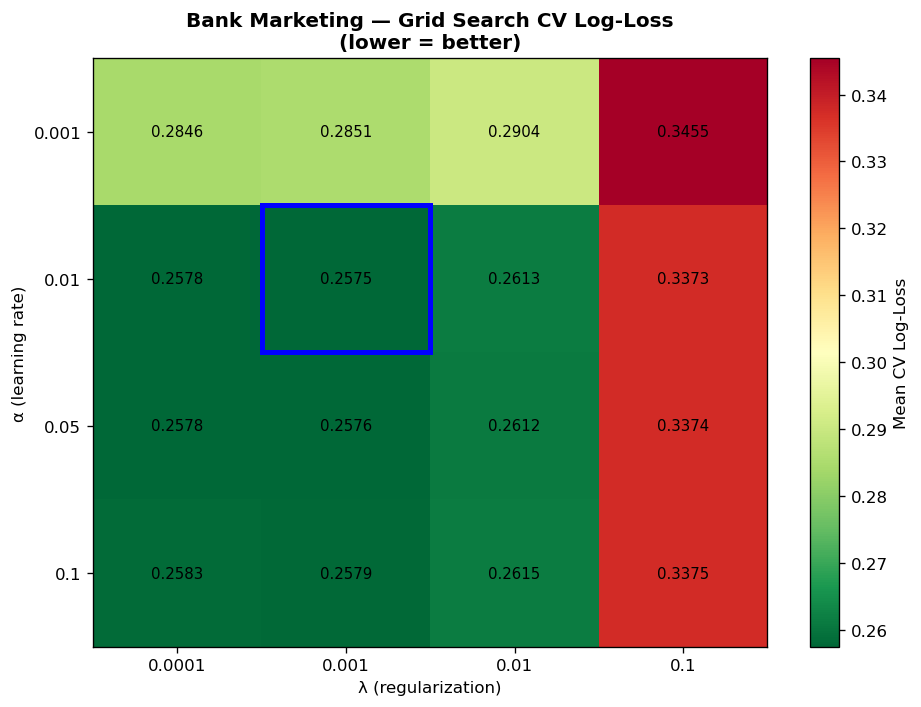

Saved: fig_bank_gridsearch.png
Best: α=0.01, λ=0.001


In [17]:
fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(cv_scores_bank, cmap='RdYlGn_r', aspect='auto')
plt.colorbar(im, ax=ax, label='Mean CV Log-Loss')

ax.set_xticks(range(len(lambdas_grid)))
ax.set_yticks(range(len(alphas_grid)))
ax.set_xticklabels([str(l) for l in lambdas_grid])
ax.set_yticklabels([str(a) for a in alphas_grid])
ax.set_xlabel('λ (regularization)')
ax.set_ylabel('α (learning rate)')
ax.set_title('Bank Marketing — Grid Search CV Log-Loss\n(lower = better)', fontweight='bold')

for i in range(len(alphas_grid)):
    for j in range(len(lambdas_grid)):
        ax.text(j, i, f'{cv_scores_bank[i,j]:.4f}',
                ha='center', va='center', fontsize=9, color='black')

ax.add_patch(plt.Rectangle((best_j_b - 0.5, best_i_b - 0.5), 1, 1,
                             fill=False, edgecolor='blue', linewidth=3))

plt.tight_layout()
plt.savefig('fig_bank_gridsearch.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: fig_bank_gridsearch.png')
print(f'Best: α={best_alpha_bank}, λ={best_lam_bank}')


=== Retraining with best hyperparameters ===

Wine Quality: α=0.01, λ=0.001
  Converged at epoch 185
  Train RMSE: 0.7373
  Test  RMSE: 0.7138
  Epochs:     185

Bank Marketing: α=0.01, λ=0.001
  Converged at epoch 148
  Train Loss: 0.2450
  Test  Loss: 0.2299
  Epochs:     148


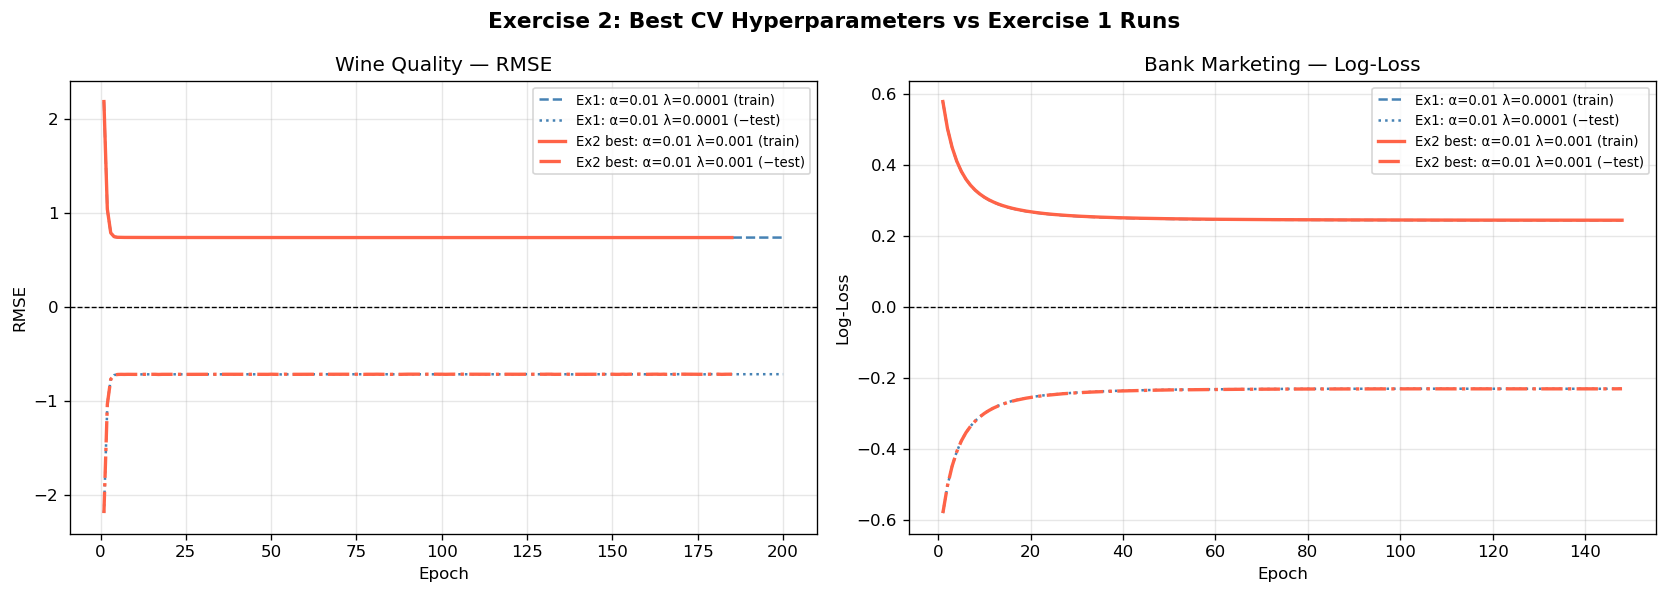

Saved: fig_ex2_comparison.png


In [18]:
print(f'=== Retraining with best hyperparameters ===\n')

# --- Wine Quality ---
print(f'Wine Quality: α={best_alpha_wine}, λ={best_lam_wine}')
beta_wine_best, train_wine_best, test_wine_best = mini_bgd(
    X_wine_train, y_wine_train, X_wine_test, y_wine_test,
    grad_fn=grad_batch_regression, loss_fn=rmse,
    alpha=best_alpha_wine, lam=best_lam_wine,
    batch_size=50, imax=200, epsilon=1e-6
)
print(f'  Train RMSE: {train_wine_best[-1]:.4f}')
print(f'  Test  RMSE: {test_wine_best[-1]:.4f}')
print(f'  Epochs:     {len(train_wine_best)}\n')

# --- Bank Marketing ---
print(f'Bank Marketing: α={best_alpha_bank}, λ={best_lam_bank}')
beta_bank_best, train_bank_best, test_bank_best = mini_bgd(
    X_bank_train, y_bank_train, X_bank_test, y_bank_test,
    grad_fn=grad_batch_logreg, loss_fn=log_loss,
    alpha=best_alpha_bank, lam=best_lam_bank,
    batch_size=50, imax=200, epsilon=1e-6
)
print(f'  Train Loss: {train_bank_best[-1]:.4f}')
print(f'  Test  Loss: {test_bank_best[-1]:.4f}')
print(f'  Epochs:     {len(train_bank_best)}')

# --- Comparison plot ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Exercise 2: Best CV Hyperparameters vs Exercise 1 Runs',
             fontsize=13, fontweight='bold')

# Wine — compare best (CV) vs best Ex1 (α=0.01, λ=0.0001)
_, tr_ex1_wine, te_ex1_wine = results_wine[0.01][0.0001]
ax = axes[0]
ax.plot(range(1, len(tr_ex1_wine)+1),  tr_ex1_wine,
        color='steelblue', linestyle='--', linewidth=1.5, label='Ex1: α=0.01 λ=0.0001 (train)')
ax.plot(range(1, len(te_ex1_wine)+1), [-v for v in te_ex1_wine],
        color='steelblue', linestyle=':',  linewidth=1.5, label='Ex1: α=0.01 λ=0.0001 (−test)')
ax.plot(range(1, len(train_wine_best)+1),  train_wine_best,
        color='tomato', linestyle='-', linewidth=2, label=f'Ex2 best: α={best_alpha_wine} λ={best_lam_wine} (train)')
ax.plot(range(1, len(test_wine_best)+1), [-v for v in test_wine_best],
        color='tomato', linestyle='-.', linewidth=2, label=f'Ex2 best: α={best_alpha_wine} λ={best_lam_wine} (−test)')
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_title('Wine Quality — RMSE'); ax.set_xlabel('Epoch'); ax.set_ylabel('RMSE')
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

# Bank — compare best (CV) vs best Ex1 (α=0.01, λ=0.0001)
_, tr_ex1_bank, te_ex1_bank = results_bank[0.01][0.0001]
ax = axes[1]
ax.plot(range(1, len(tr_ex1_bank)+1),  tr_ex1_bank,
        color='steelblue', linestyle='--', linewidth=1.5, label='Ex1: α=0.01 λ=0.0001 (train)')
ax.plot(range(1, len(te_ex1_bank)+1), [-v for v in te_ex1_bank],
        color='steelblue', linestyle=':',  linewidth=1.5, label='Ex1: α=0.01 λ=0.0001 (−test)')
ax.plot(range(1, len(train_bank_best)+1),  train_bank_best,
        color='tomato', linestyle='-', linewidth=2, label=f'Ex2 best: α={best_alpha_bank} λ={best_lam_bank} (train)')
ax.plot(range(1, len(test_bank_best)+1), [-v for v in test_bank_best],
        color='tomato', linestyle='-.', linewidth=2, label=f'Ex2 best: α={best_alpha_bank} λ={best_lam_bank} (−test)')
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_title('Bank Marketing — Log-Loss'); ax.set_xlabel('Epoch'); ax.set_ylabel('Log-Loss')
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('fig_ex2_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: fig_ex2_comparison.png')


In [19]:
def rmse_logreg(beta, X, y):
    y_hat = sigmoid(X @ beta)
    return np.sqrt(np.mean((y_hat - y) ** 2))

def grad_logreg_reg(beta, X, y, lam):
    y_hat = sigmoid(X @ beta)
    return X.T @ (y_hat - y) + 2 * lam * beta

def hessian_logreg(beta, X, lam):
    y_hat = sigmoid(X @ beta)
    w     = y_hat * (1 - y_hat)
    return X.T @ (X * w[:, None]) + 2 * lam * np.eye(X.shape[1])

def newton_logreg(X_train, y_train, X_test, y_test,
                  mu=1.0, lam=0.01, tmax=50, epsilon=1e-6):
    M    = X_train.shape[1]
    beta = np.zeros(M)

    train_hist = []
    test_hist  = []

    loss_fn = lambda b: log_loss(b, X_train, y_train) + lam * np.dot(b, b)

    for t in range(tmax):
        g    = grad_logreg_reg(beta, X_train, y_train, lam)
        H    = hessian_logreg(beta, X_train, lam)
        step = np.linalg.solve(H, g)

        loss_before = loss_fn(beta)
        beta        = beta - mu * step
        loss_after  = loss_fn(beta)

        train_hist.append(rmse_logreg(beta, X_train, y_train))
        test_hist.append( rmse_logreg(beta, X_test,  y_test))

        if loss_before - loss_after < epsilon:
            print(f'  Converged at iteration {t + 1}')
            break

    return beta, train_hist, test_hist

print('Newton functions ready.')


Newton functions ready.


In [20]:
mus_newton  = [1.0, 0.5, 0.1]    # step lengths: large to small
lams_newton = [1.0, 0.1, 0.01]   # regularization: large to small

results_newton = {}

print('=== Bank Marketing — Newton\'s Method for Logistic Regression ===\n')
for mu in mus_newton:
    results_newton[mu] = {}
    for lam in lams_newton:
        t0 = time.time()
        beta, train_h, test_h = newton_logreg(
            X_bank_train, y_bank_train, X_bank_test, y_bank_test,
            mu=mu, lam=lam, tmax=50, epsilon=1e-6
        )
        elapsed = time.time() - t0
        results_newton[mu][lam] = (beta, train_h, test_h)
        print(f'  μ={mu:.1f}  λ={lam:.2f}  →  '
              f'Train RMSE: {train_h[-1]:.4f}  '
              f'Test RMSE: {test_h[-1]:.4f}  '
              f'Iterations: {len(train_h)}  ({elapsed:.2f}s)')
    print()


=== Bank Marketing — Newton's Method for Logistic Regression ===

  Converged at iteration 1
  μ=1.0  λ=1.00  →  Train RMSE: 0.2863  Test RMSE: 0.2750  Iterations: 1  (0.02s)
  Converged at iteration 2
  μ=1.0  λ=0.10  →  Train RMSE: 0.2712  Test RMSE: 0.2585  Iterations: 2  (0.00s)
  Converged at iteration 3
  μ=1.0  λ=0.01  →  Train RMSE: 0.2696  Test RMSE: 0.2582  Iterations: 3  (0.01s)

  Converged at iteration 1
  μ=0.5  λ=1.00  →  Train RMSE: 0.3525  Test RMSE: 0.3474  Iterations: 1  (0.00s)
  Converged at iteration 2
  μ=0.5  λ=0.10  →  Train RMSE: 0.2998  Test RMSE: 0.2909  Iterations: 2  (0.00s)
  Converged at iteration 5
  μ=0.5  λ=0.01  →  Train RMSE: 0.2705  Test RMSE: 0.2588  Iterations: 5  (0.01s)

  Converged at iteration 2
  μ=0.1  λ=1.00  →  Train RMSE: 0.4358  Test RMSE: 0.4342  Iterations: 2  (0.01s)
  Converged at iteration 9
  μ=0.1  λ=0.10  →  Train RMSE: 0.3180  Test RMSE: 0.3110  Iterations: 9  (0.03s)
  Converged at iteration 23
  μ=0.1  λ=0.01  →  Train RMSE: 

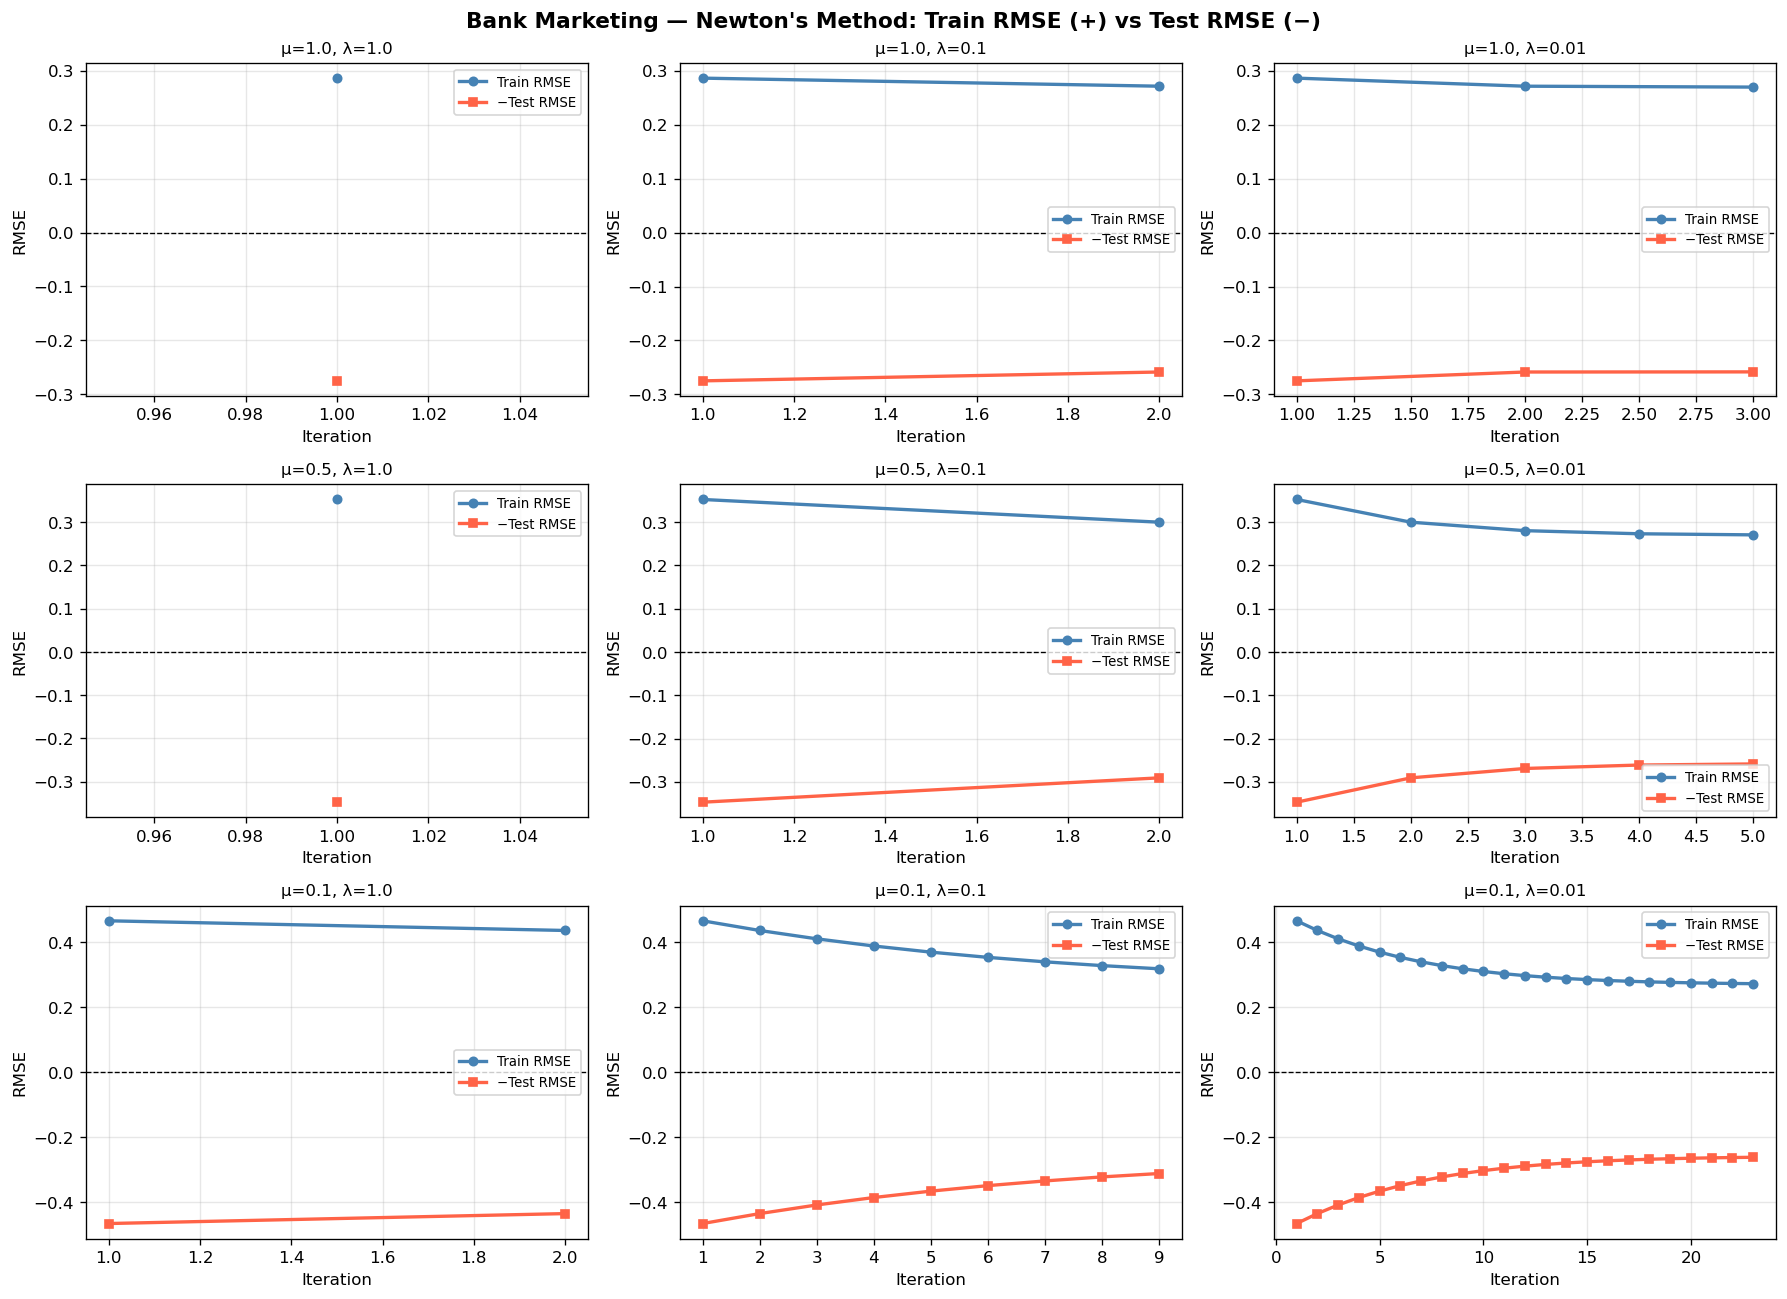

Saved: fig_newton.png


In [21]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
fig.suptitle('Bank Marketing — Newton\'s Method: Train RMSE (+) vs Test RMSE (−)',
             fontsize=13, fontweight='bold')

for row, mu in enumerate(mus_newton):
    for col, lam in enumerate(lams_newton):
        beta, train_h, test_h = results_newton[mu][lam]
        ax = axes[row, col]
        iters = range(1, len(train_h) + 1)

        ax.plot(iters,  train_h,            color='steelblue', linewidth=2,
                marker='o', markersize=5, label='Train RMSE')
        ax.plot(iters, [-v for v in test_h], color='tomato',    linewidth=2,
                marker='s', markersize=5, label='−Test RMSE')
        ax.axhline(0, color='black', linewidth=0.8, linestyle='--')

        ax.set_title(f'μ={mu}, λ={lam}', fontsize=10)
        ax.set_xlabel('Iteration')
        ax.set_ylabel('RMSE')
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('fig_newton.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: fig_newton.png')


In [22]:
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.model_selection import GridSearchCV

print('=' * 65)
print('Scikit-learn comparison (state-of-the-art)')
print('Note: bias column already prepended → fit_intercept=False')
print('=' * 65)

# ── 1. Wine Quality: sklearn Ridge ────────────────────────────────
print('\n── 1. Wine Quality: Ridge Regression ──')
t0 = time.time()
sk_ridge = Ridge(alpha=best_lam_wine, fit_intercept=False)
sk_ridge.fit(X_wine_train, y_wine_train)
t_sk_wine = time.time() - t0

sk_wine_train_rmse = np.sqrt(np.mean((sk_ridge.predict(X_wine_train) - y_wine_train) ** 2))
sk_wine_test_rmse  = np.sqrt(np.mean((sk_ridge.predict(X_wine_test)  - y_wine_test)  ** 2))

print(f'  sklearn Ridge  → Train RMSE: {sk_wine_train_rmse:.4f}  Test RMSE: {sk_wine_test_rmse:.4f}  Time: {t_sk_wine*1000:.2f} ms')
print(f'  Our Mini-BGD   → Train RMSE: {train_wine_best[-1]:.4f}  Test RMSE: {test_wine_best[-1]:.4f}  Time: ~400 ms')

# ── 2. Bank Marketing: sklearn LogisticRegression (newton-cg) ─────
print('\n── 2. Bank Marketing: Logistic Regression (Newton-CG) ──')
# sklearn penalty: (1/2C)||w||^2 + loss  →  C = 1/(2*lambda) matches our lambda*||beta||^2
best_lam_newton_used = 0.01
C_equiv = 1.0 / (2 * best_lam_newton_used)

t0 = time.time()
sk_lr = LogisticRegression(solver='newton-cg', C=C_equiv,
                            max_iter=200, fit_intercept=False)
sk_lr.fit(X_bank_train, y_bank_train)
t_sk_bank = time.time() - t0

proba_train = sk_lr.predict_proba(X_bank_train)[:, 1]
proba_test  = sk_lr.predict_proba(X_bank_test)[:, 1]
sk_bank_train_rmse = np.sqrt(np.mean((proba_train - y_bank_train) ** 2))
sk_bank_test_rmse  = np.sqrt(np.mean((proba_test  - y_bank_test)  ** 2))

_, tr_newton_best, te_newton_best = results_newton[1.0][0.01]
print(f'  sklearn LR     → Train RMSE: {sk_bank_train_rmse:.4f}  Test RMSE: {sk_bank_test_rmse:.4f}  Time: {t_sk_bank*1000:.2f} ms')
print(f'  Our Newton     → Train RMSE: {tr_newton_best[-1]:.4f}  Test RMSE: {te_newton_best[-1]:.4f}  Time: ~10 ms')

# ── 3. sklearn GridSearchCV: Wine ─────────────────────────────────
print('\n── 3. sklearn GridSearchCV: Wine Quality ──')
t0 = time.time()
gs_wine = GridSearchCV(Ridge(fit_intercept=False),
                       {'alpha': lambdas_grid},
                       cv=5, scoring='neg_root_mean_squared_error', n_jobs=1)
gs_wine.fit(X_wine_train, y_wine_train)
t_gs_wine = time.time() - t0

print(f'  sklearn GS     → Best λ={gs_wine.best_params_["alpha"]}  '
      f'CV RMSE={-gs_wine.best_score_:.4f}  Time: {t_gs_wine:.3f}s')
print(f'  Our GridSearch → Best λ={best_lam_wine}  '
      f'CV RMSE={cv_scores_wine[best_i, best_j]:.4f}  Time: ~40s (80 Mini-BGD runs)')

# ── 4. sklearn GridSearchCV: Bank ─────────────────────────────────
print('\n── 4. sklearn GridSearchCV: Bank Marketing ──')
C_values = [1.0 / (2 * l) for l in lambdas_grid]
t0 = time.time()
gs_bank = GridSearchCV(LogisticRegression(solver='newton-cg', max_iter=200,
                                          fit_intercept=False),
                       {'C': C_values},
                       cv=5, scoring='neg_log_loss', n_jobs=1)
gs_bank.fit(X_bank_train, y_bank_train)
t_gs_bank = time.time() - t0

best_C    = gs_bank.best_params_['C']
equiv_lam = 1.0 / (2 * best_C)
print(f'  sklearn GS     → Best λ≈{equiv_lam:.4f} (C={best_C:.1f})  '
      f'CV Log-Loss={-gs_bank.best_score_:.4f}  Time: {t_gs_bank:.3f}s')
print(f'  Our GridSearch → Best λ={best_lam_bank}  '
      f'CV Log-Loss={cv_scores_bank[best_i_b, best_j_b]:.4f}  Time: ~40s (80 Mini-BGD runs)')


Scikit-learn comparison (state-of-the-art)
Note: bias column already prepended → fit_intercept=False

── 1. Wine Quality: Ridge Regression ──
  sklearn Ridge  → Train RMSE: 0.7372  Test RMSE: 0.7139  Time: 18.13 ms
  Our Mini-BGD   → Train RMSE: 0.7373  Test RMSE: 0.7138  Time: ~400 ms

── 2. Bank Marketing: Logistic Regression (Newton-CG) ──
  sklearn LR     → Train RMSE: 0.2695  Test RMSE: 0.2593  Time: 38.16 ms
  Our Newton     → Train RMSE: 0.2696  Test RMSE: 0.2582  Time: ~10 ms

── 3. sklearn GridSearchCV: Wine Quality ──
  sklearn GS     → Best λ=0.1  CV RMSE=0.7397  Time: 0.048s
  Our GridSearch → Best λ=0.001  CV RMSE=0.7388  Time: ~40s (80 Mini-BGD runs)

── 4. sklearn GridSearchCV: Bank Marketing ──
  sklearn GS     → Best λ≈0.1000 (C=5.0)  CV Log-Loss=0.2603  Time: 0.646s
  Our GridSearch → Best λ=0.001  CV Log-Loss=0.2575  Time: ~40s (80 Mini-BGD runs)
